In [ ]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
import numpy as np
import random
SEED = 0
np.random.seed(SEED)
random.seed(SEED)

from matplotlib.colors import LinearSegmentedColormap

my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)





figure_save_path = "../results/Fig_9_figures"
os.makedirs(figure_save_path, exist_ok=True)

In [8]:
adata_full = sc.read("../data/WL_Cultured_SCVI_min.h5ad")

## Fig. 9a

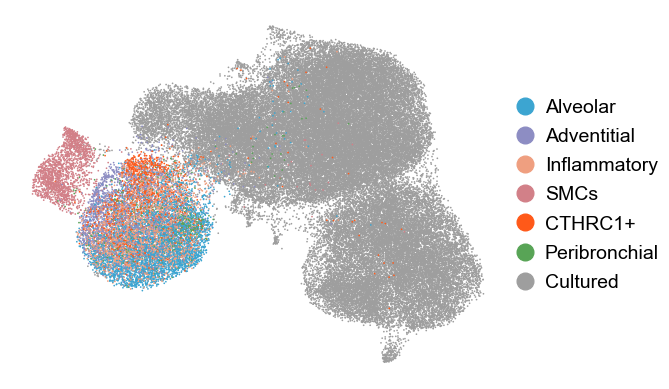

In [10]:
with plt.rc_context({"font.size": 14, "legend.fontsize": 14,
                    "legend.markerscale": 2.0}):
    fig = sc.pl.umap(
        adata_full,
        color=["manual_annotation"],
        frameon=False,
        size=6,
        title='',
        show=False,
        return_fig=True
    )
    fig.savefig(f"{figure_save_path}/WL_annotation.pdf", bbox_inches='tight')
    plt.show()

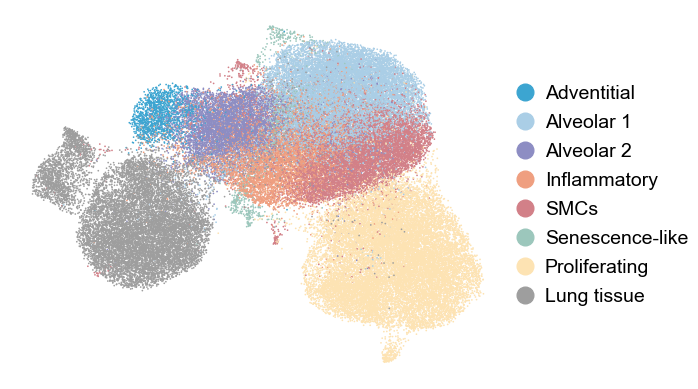

In [11]:
with plt.rc_context({"font.size": 14, "legend.fontsize": 14,
                    "legend.markerscale": 2.0}):
    fig = sc.pl.umap(
        adata_full,
        color="annotation",
        frameon=False,
        title="",
        show=False,
        size=6,
        return_fig=True
    )
    fig.savefig(f"{figure_save_path}/Cultured_annotation.pdf", bbox_inches="tight")
    plt.show()

## Fig. 9b

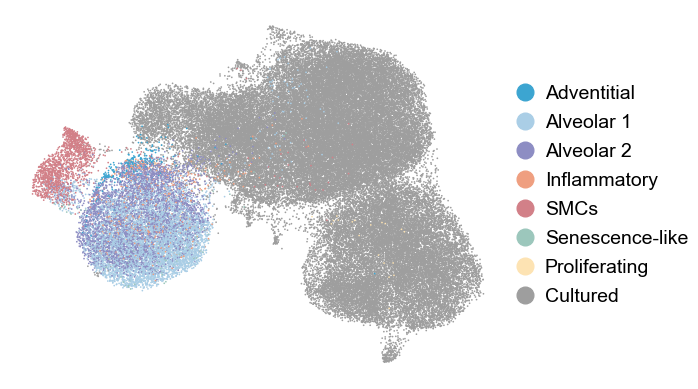

In [13]:
with plt.rc_context({"font.size": 14, "legend.fontsize": 14,
                    "legend.markerscale": 2.0}):
    fig = sc.pl.umap(
        adata_full,
        color=["annotation_pred"],
        frameon=False,
        size=6,
        title='',
        show=False,
        return_fig=True
    )
    fig.savefig(f"{figure_save_path}/combined_lung_tissue_prediction.pdf", bbox_inches='tight')
    plt.show()

## Fig. 9c

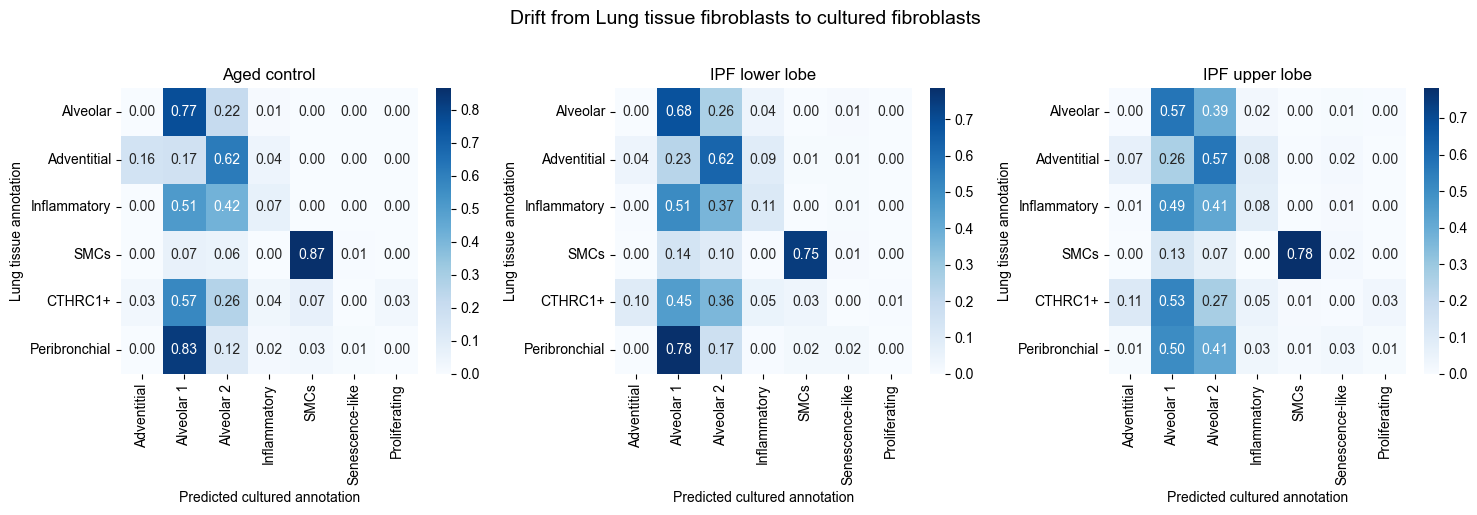

In [ ]:
wl_adata = adata_full[adata_full.obs['Protocol'] == 'Lung Tissue']
conditions = ['Aged control', 'IPF lower lobe', 'IPF upper lobe']
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, con in zip(axes, conditions):
    wl_con_adata = wl_adata[wl_adata.obs['Condition'] == con]
    conf_df = pd.crosstab(
        wl_con_adata.obs["manual_annotation"],
        wl_con_adata.obs["annotation_pred"],
        normalize="index"
    )
    sns.heatmap(conf_df, cmap="Blues", annot=True, fmt=".2f", ax=ax)
    ax.set_title(f"{con}")

    ax.set_xlabel("Predicted cultured annotation")
    ax.set_ylabel("Lung tissue annotation")

plt.suptitle("Drift from Lung tissue fibroblasts to cultured fibroblasts", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{figure_save_path}/Separate_condition_wl_to_cultured.pdf", bbox_inches='tight')
plt.show()
